In [1]:
# %matplotlib widget
import matplotlib.pyplot as plt
import numpy as np
np.random.seed(1234567)
from collections import OrderedDict
import astropy.units as u
import math

import multiprocessing as mul

from pyLIMA.fits import TRF_fit
from pyLIMA.models import PSPL_model, PSBL_model, USBL_model
from pyLIMA.outputs import pyLIMA_plots

from pyLIMA import event
from pyLIMA import telescopes

path = '../../examples/data/'

In [2]:
event_1 = event.Event(ra=268.75425, dec=-29.047111111111114)
event_1.name = 'OB150966'

data_1 = np.loadtxt(path + 'OGLE_OB150966.dat')
telescope_1 = telescopes.Telescope(name = 'OGLE', 
                                   camera_filter = 'I',
                                   lightcurve = data_1.astype(float),
                                   lightcurve_names = ['time','mag','err_mag'],
                                   lightcurve_units = ['JD','mag','mag'])

data_2 = np.loadtxt(path + 'MOA_OB150966.dat')
telescope_2 = telescopes.Telescope(name = 'MOA', 
                                   camera_filter = 'I+R',
                                   lightcurve = data_2.astype(float),
                                   lightcurve_names = ['time','mag','err_mag'],
                                   lightcurve_units = ['JD','mag','mag'])

data_3 = np.loadtxt(path + 'SPITZER_OB150966.dat')
telescope_3 = telescopes.Telescope(name = 'SPITZER', 
                                   camera_filter = 'IRAC1',
                                   lightcurve = data_3.astype(float),
                                   lightcurve_names = ['time','mag','err_mag'],
                                   lightcurve_units = ['JD','mag','mag'])

telescope_3.location = 'Space'
telescope_3.spacecraft_name = 'Spitzer'

data_4 = np.loadtxt(path + 'DANISH_OB150966.dat')
telescope_4 = telescopes.Telescope(name = 'DANISH', 
                                   camera_filter = 'Z+I',
                                   lightcurve = data_4.astype(float),
                                   lightcurve_names = ['time','mag','err_mag'],
                                   lightcurve_units = ['JD','mag','mag'])

data_5 = np.loadtxt(path + 'LCO_CTIO_A_OB150966.dat')
telescope_5 = telescopes.Telescope(name = 'LCO_CTIO_A', 
                                   camera_filter = 'I',
                                   lightcurve = data_5.astype(float),
                                   lightcurve_names = ['time','mag','err_mag'],
                                   lightcurve_units = ['JD','mag','mag'])

data_6 = np.loadtxt(path + 'LCO_CTIO_B_OB150966.dat')
telescope_6 = telescopes.Telescope(name = 'LCO_CTIO_B', 
                                   camera_filter = 'I',
                                   lightcurve = data_6.astype(float),
                                   lightcurve_names = ['time','mag','err_mag'],
                                   lightcurve_units = ['JD','mag','mag'])

data_7 = np.loadtxt(path + 'LCO_CTIO_OB150966.dat')
telescope_7 = telescopes.Telescope(name = 'LCO_CTIO', 
                                   camera_filter = 'I',
                                   lightcurve = data_7.astype(float),
                                   lightcurve_names = ['time','mag','err_mag'],
                                   lightcurve_units = ['JD','mag','mag'])

data_8 = np.loadtxt(path + 'LCO_SAAO_OB150966.dat')
telescope_8 = telescopes.Telescope(name = 'LCO_SAAO', 
                                   camera_filter = 'I',
                                   lightcurve = data_8.astype(float),
                                   lightcurve_names = ['time','mag','err_mag'],
                                   lightcurve_units = ['JD','mag','mag'])

data_9 = np.loadtxt(path + 'LCO_SSO_A_OB150966.dat')
telescope_9 = telescopes.Telescope(name = 'LCO_SSO_A', 
                                   camera_filter = 'I',
                                   lightcurve = data_9.astype(float),
                                   lightcurve_names = ['time','mag','err_mag'],
                                   lightcurve_units = ['JD','mag','mag'])

data_10 = np.loadtxt(path + 'LCO_SSO_B_OB150966.dat')
telescope_10 = telescopes.Telescope(name = 'LCO_SSO_B', 
                                   camera_filter = 'I',
                                   lightcurve = data_10.astype(float),
                                   lightcurve_names = ['time','mag','err_mag'],
                                   lightcurve_units = ['JD','mag','mag'])

data_11 = np.loadtxt(path + 'LCO_SSO_OB150966.dat')
telescope_11 = telescopes.Telescope(name = 'LCO_SSO', 
                                   camera_filter = 'I',
                                   lightcurve = data_11.astype(float),
                                   lightcurve_names = ['time','mag','err_mag'],
                                   lightcurve_units = ['JD','mag','mag'])

event_1.telescopes.append(telescope_1)
event_1.telescopes.append(telescope_2)
# event_1.telescopes.append(telescope_3)
event_1.telescopes.append(telescope_4)
event_1.telescopes.append(telescope_5)
event_1.telescopes.append(telescope_6)
event_1.telescopes.append(telescope_7)
event_1.telescopes.append(telescope_8)
# event_1.telescopes.append(telescope_9)
# event_1.telescopes.append(telescope_10)
# event_1.telescopes.append(telescope_11)

event_1.find_survey('OGLE')

event_1.check_event()

check_event  : Everything looks fine...


check_event  : Everything looks fine...
[2457205.21, 0.309, 10.7821, 1.3, 0.001, 1.9, np.float64(10000.0), np.float64(12000.0)]


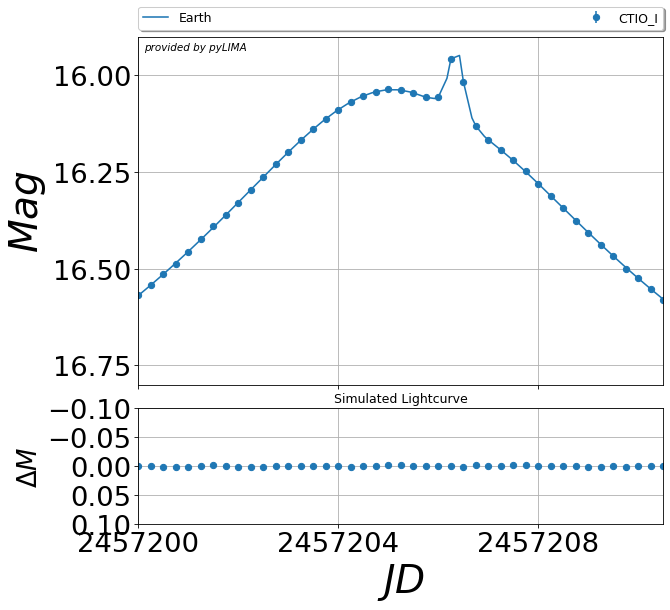

In [3]:
from pyLIMA.simulations import simulator

event_3 = event.Event(ra=270, dec=0)
event_3.name = 'My simulated event'

CTIO_I = simulator.simulate_a_telescope(name='CTIO_I', time_start=2457190, time_end=2457220, sampling=6, 
                                        location='Earth', camera_filter='I',
                                        uniform_sampling=True, astrometry=False)
# LCO_SAAO = simulator.simulate_a_telescope(name='LCO_SAAO', time_start=2457205, time_end=2457208, sampling=1, 
#                                         location='Earth', camera_filter='I',
#                                         uniform_sampling=True, astrometry=False)

event_3.telescopes.append(CTIO_I)
# event_3.telescopes.append(LCO_SAAO)
event_3.check_event()

psbl_sim = PSBL_model.PSBLmodel(event_3)
psbl_sim_params = simulator.simulate_microlensing_model_parameters(psbl_sim)

### Set the parameters to some reasonable values.
psbl_sim_params[0] = 2457205.21 # t0
psbl_sim_params[1:3] = [0.309, 10.7821] # u0, tE
psbl_sim_params[3:6] = [1.3, 0.001, 1.9] # s, q, alpha

### Set the source and blend fluxes of all telescopes to the same values for plotting purposes.
n_tel = len(event_3.telescopes)
psbl_sim_params[-n_tel*2::2] = 10000. * np.ones(n_tel) # source fluxes
psbl_sim_params[-n_tel*2+1::2] = 12000. * np.ones(n_tel) # total fluxes
print(psbl_sim_params)

### Transform the parameters into a pyLIMA class object.
pyLIMA_parameters_1 = psbl_sim.compute_pyLIMA_parameters(psbl_sim_params)

### Inject everthing into the simulator to produce a light curve.
simulator.simulate_lightcurve(psbl_sim, pyLIMA_parameters_1)

pyLIMA_plots.plot_lightcurves(psbl_sim, psbl_sim_params)
plt.title('Simulated Lightcurve')
plt.gcf().axes[0].set_xlim(2457200.0, 2457210.5)
plt.gcf().axes[0].set_ylim(16.8, 15.9)
plt.show()

In [4]:
# Select event
my_event = event_3

# set window limits
if my_event == event_1:
    ax_xlim = (2457204.0, 2457206.5)
    ax_ylim = (15.50, 14.40)
if my_event == event_3:
    ax_xlim = (2457200.0, 2457210.5)
    ax_ylim = (16.8, 15.9)

Selecting CTIO_I to estimate u0, tE and fs
initial_guess  : Initial parameters guess SUCCESS
Using guess:  [2457205.25, 0.4732909888210218, 5.5, 18578.84119624983, 14329.112931459389]
Trust Region Reflective fit SUCCESS
best model:
OrderedDict([('t0', np.float64(2457205.1941240197)),
             ('u0', np.float64(0.31064273065901393)),
             ('tE', np.float64(10.840483880941157)),
             ('fsource_CTIO_I', np.float64(9928.251038436849)),
             ('ftotal_CTIO_I', np.float64(11987.804747889439)),
             ('soft_l1', np.float64(711.5223123027208))])


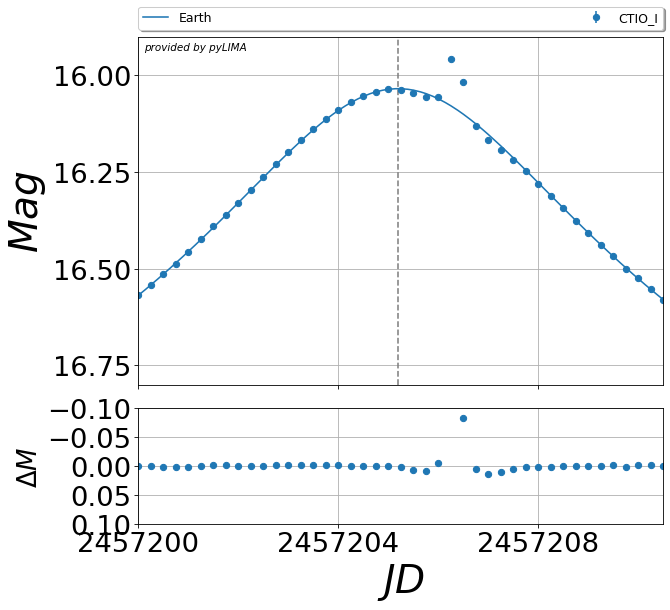

In [5]:
# PSPL model
pspl = PSPL_model.PSPLmodel(my_event)
# Robust fit
fit = TRF_fit.TRFfit(pspl, loss_function='soft_l1')
if my_event == event_1:
    fit.model_parameters_guess = [2457205.5, 1.0, 100.0]
fit.fit()
pspl_params =  OrderedDict(zip(fit.priors_parameters.keys(), fit.fit_results['best_model']))

# Plot
fig, _ = pyLIMA_plots.plot_lightcurves(pspl, fit.fit_results['best_model'])
# Set the window dimension.
fig.axes[0].set_xlim(*ax_xlim)
fig.axes[0].set_ylim(*ax_ylim)

# Line at t0
fig.axes[0].axvline(pspl_params['t0'], color='gray', linestyle='--')
plt.show()

In [6]:
import reldev_grid as rd
verbose = False

# assumptions
q = 0.001 
rs = 0.0005

# get parameters from pspl fit
# print(params)
t0 = pspl_params['t0']
u0 = pspl_params['u0']
te = pspl_params['tE']

# algorithm parameters
t_range = (t0 - 5, t0 + 5) # distance from t0 to compute reldev [in JD]

# Setup Meshgrid
x_min = -2.0
x_max = 2.0
y_min = -2.0
y_max = 2.0
resolution = 100
x_range = np.linspace(x_min, x_max, resolution)
y_range = np.linspace(y_min, y_max, resolution)
X_grid, Y_grid = np.meshgrid(x_range, y_range)

# Setup dict for saving values while running
reldev_maps = {}
reldev_maps['t'] = []
reldev_maps['name'] = []
reldev_maps['weight'] = []
reldev_maps['detection_zone'] = []

# per telescope
for telescope in my_event.telescopes:

    name = telescope.name
    # telescope parameters from fit
    fs = pspl_params['fsource_' + name]
    fb = pspl_params['ftotal_' + name] - pspl_params['fsource_' + name]

    # crop lightcurve to t_range
    time = telescope.lightcurve['time'].value
    lightcurve = telescope.lightcurve[(time > t_range[0]) & (time < t_range[1])]

    # per datapoint
    for datapoint in lightcurve:

        # parameters from datapoint
        t = datapoint['time'].value # in [JD]
        try:
            freal = datapoint['flux'].value
            ferr = datapoint['err_flux'].value # in [W/m^2]
        except:
            freal = datapoint['flux']
            ferr = datapoint['err_flux']

        # setup a vectorized function to compute reldev at each point
        def vectorized_reldev_wrapper(X_arr, Y_arr):
            vectorized_func = np.vectorize(lambda x, y: rd.reldev(q, t, u0, te, t0, fs, fb, ferr, rs, x, y))
            return vectorized_func(X_arr, Y_arr)
        # TODO: remove this vectorized function wrapper declaration for performance
        
        # compute reldev values on meshgrid
        if verbose:
            print(f'Running Grid Analysis for {name} at t={t}.')
        Z = vectorized_reldev_wrapper(X_grid, Y_grid)

        # compute weight by difference of pspl and real flux
        pspl = rd.pspl_n_imagesf(t, u0, te, t0)[0]
        fmodel = fs * pspl + fb
        weight = (freal - fmodel)**2 / ferr**2 # use delta chisq 
        if verbose:
            print('real:', freal, ' model:', fmodel, ' weight:', weight)

        # save
        reldev_maps['t'].append(t)
        reldev_maps['name'].append(name)
        reldev_maps['weight'].append(weight)
        reldev_maps['detection_zone'].append(Z)

# average the reldev maps
detection_zone_map = np.average(reldev_maps['detection_zone'], axis=0)
planet_anomaly_map = np.average(reldev_maps['detection_zone'], axis=0, weights=reldev_maps['weight'])

print('Done.')

Done.


40 4 10


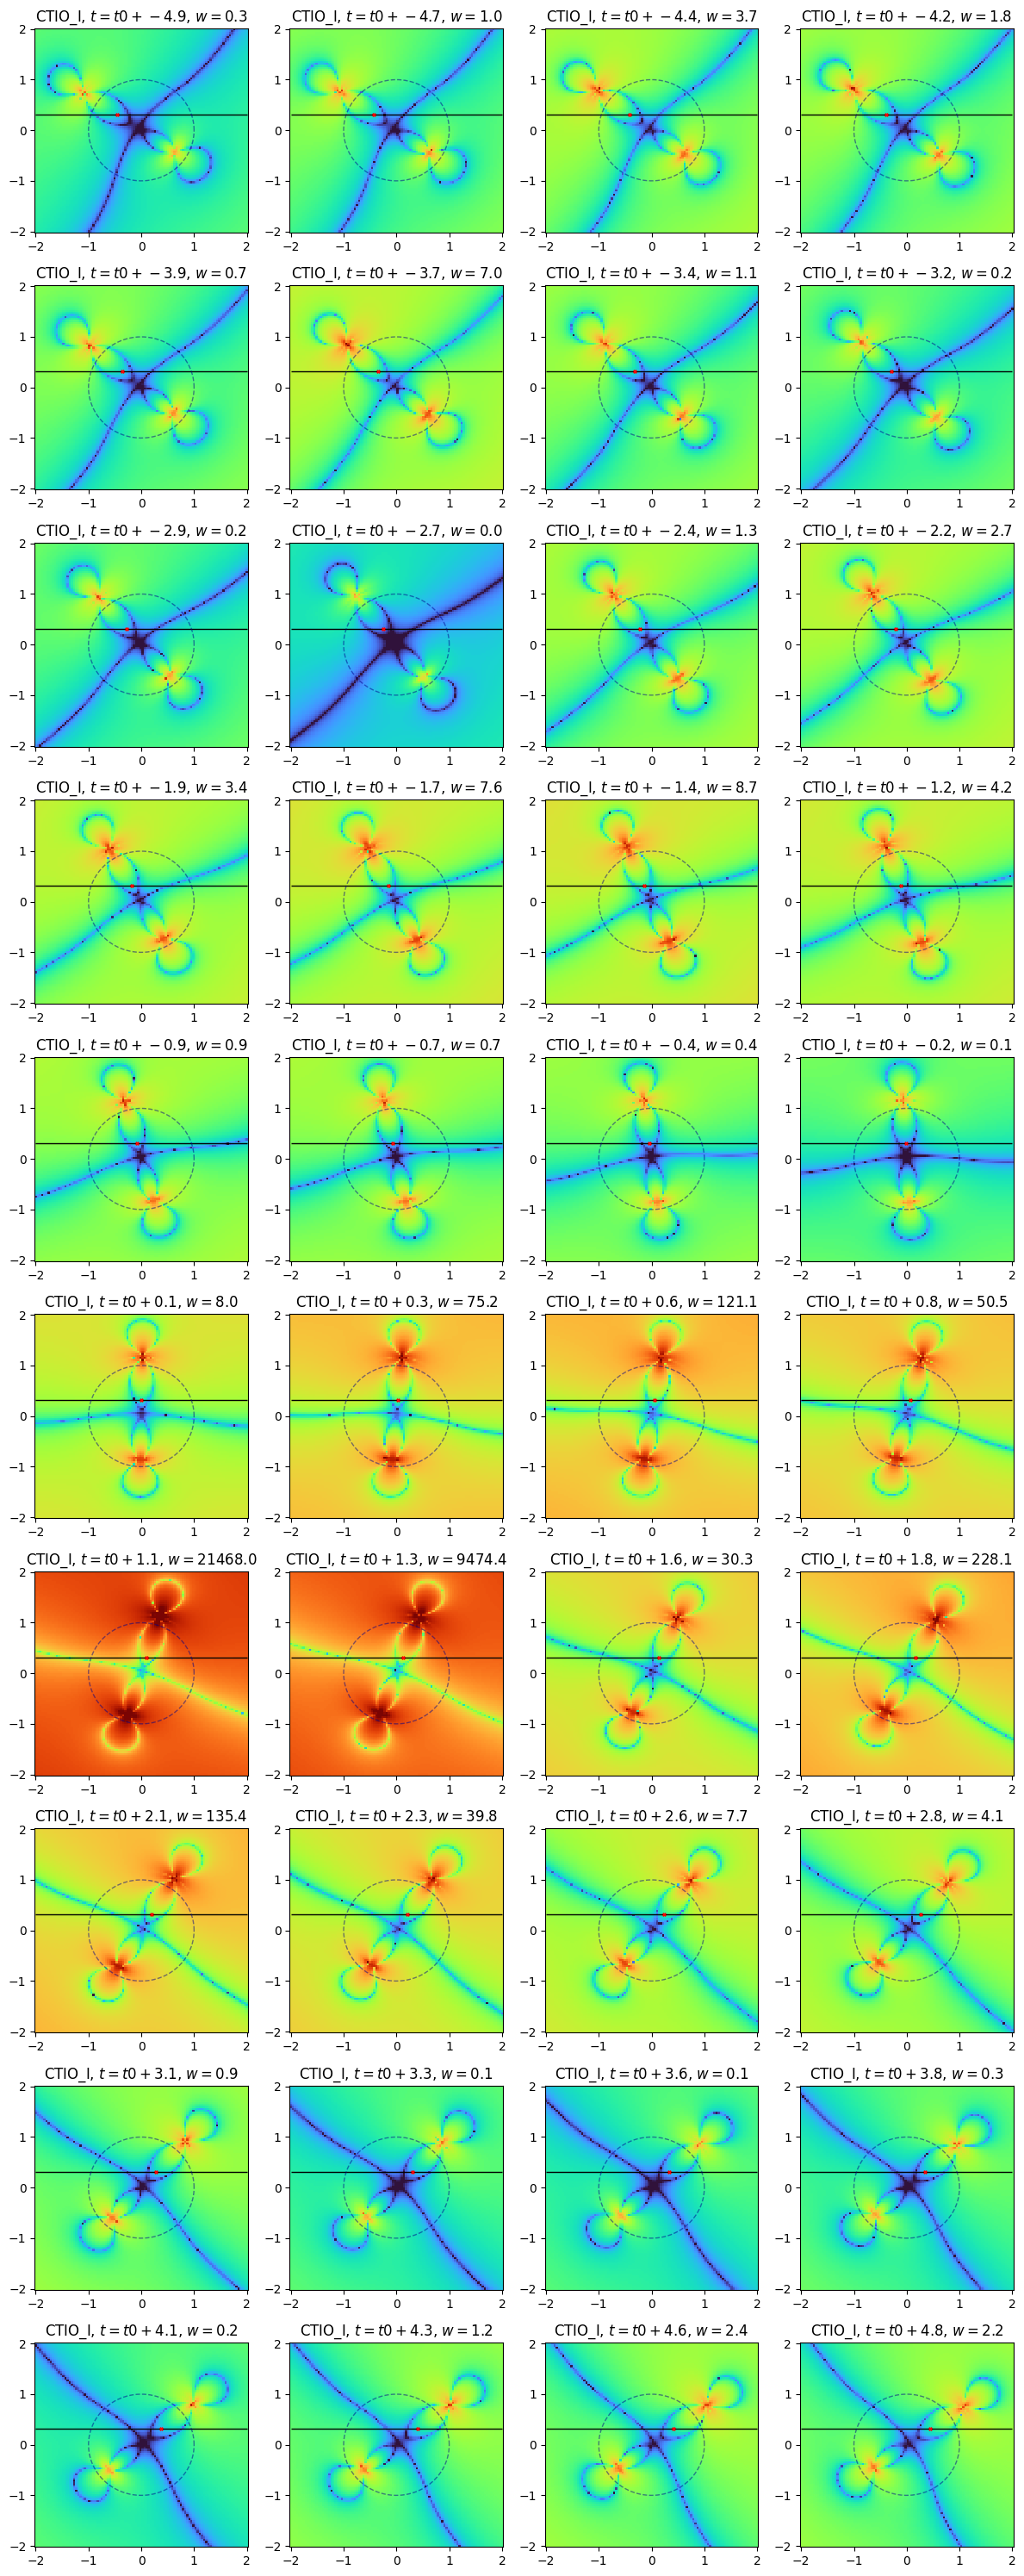

In [7]:
# Figure of all individual maps
import matplotlib.cm as cm
import matplotlib.colors as colors

n_maps = len(reldev_maps['detection_zone']) 
nx_maps = 4
ny_maps = math.ceil(n_maps/nx_maps)
print(n_maps, nx_maps, ny_maps)

plt.figure(figsize=(3*nx_maps, 3*ny_maps))
# plt.suptitle('Relative deviation caused by 2nd lens $\\log_{10}(\\Delta\\mu/\\mu$))')

for i in range(n_maps):
    # unpack
    name = reldev_maps['name'][i]
    t = reldev_maps['t'][i]
    map = reldev_maps['detection_zone'][i]
    weight = reldev_maps['weight'][i]

    # create subplot
    plt.subplot(ny_maps, nx_maps, i+1)
    plt.title(f'{name}, $t = t0 + {t - t0:.1f}$, $w = {weight:.1f}$')

    # heatmap
    norm = colors.LogNorm(1e-5, 1e8)
    plt.pcolormesh(X_grid, Y_grid, map*weight, shading='auto', cmap=cm.turbo, norm=norm)

    # trajectory
    plt.hlines(u0, xmin=np.min(X_grid), xmax=np.max(X_grid), 
        linestyle='-', lw=1, color='k', label="Source Trajectory")
    plt.scatter((t - t0) / te, u0, 
                s=6, c='red', marker='x', label='Source Pos. at Obs.', zorder=2)
    
    # Einstein ring
    theta = np.linspace(0, 2 * np.pi, 100)
    x = 1 * np.cos(theta)
    y = 1 * np.sin(theta)
    plt.plot(x, y, linestyle='--', lw=1, alpha=0.5, color='darkblue', label="$\\theta_E$")

# show
plt.tight_layout()
plt.show()

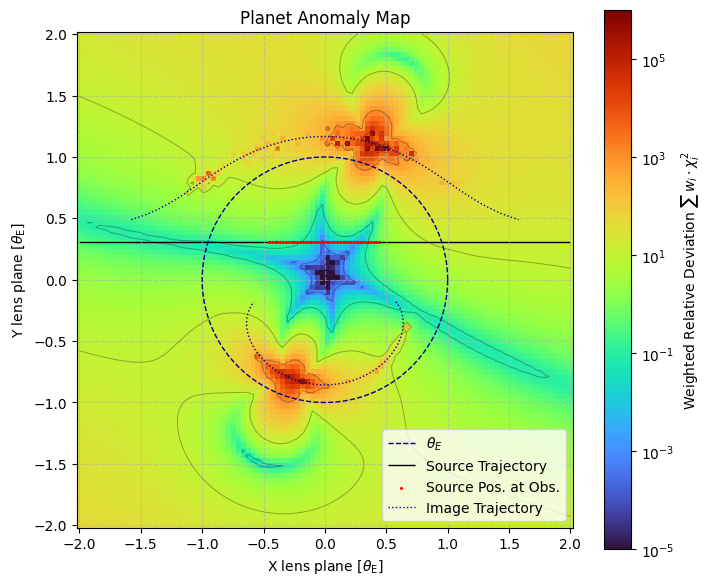

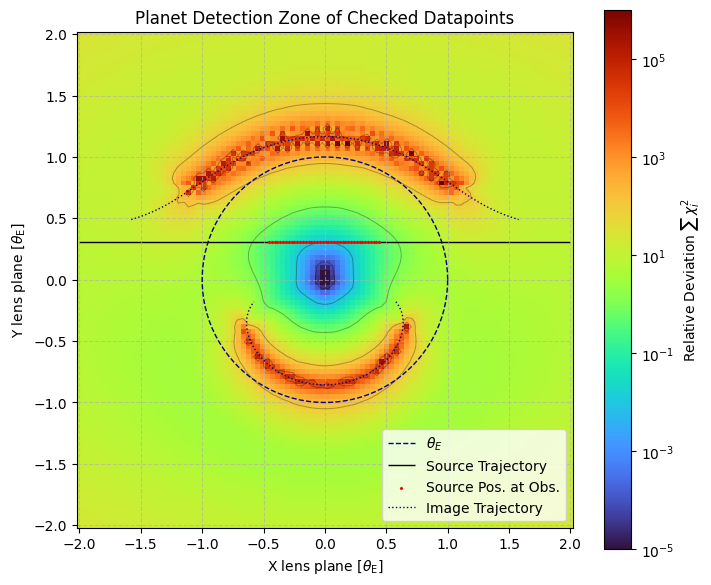

In [8]:
### Heatmap Plot
rd.plot_heatmap(X_grid, Y_grid, planet_anomaly_map, 
                norm=colors.LogNorm(1e-5,1e6),
                add_cbar=True, cbar_label='Weighted Relative Deviation $\\sum \\, w_i \\cdot \\chi_i^2$',
                add_contour=True, add_grid=True, add_tE=True,
                add_trajectory=True, t0=t0, u0=u0, te=te, t=reldev_maps['t'],
                show_plot=False)
plt.title('Planet Anomaly Map')
plt.show()

rd.plot_heatmap(X_grid, Y_grid, detection_zone_map, 
                norm=colors.LogNorm(1e-5,1e6),
                add_cbar=True, cbar_label='Relative Deviation $\\sum \\, \\chi_i^2$',
                add_contour=True, add_grid=True, add_tE=True,
                add_trajectory=True, t0=t0, u0=u0, te=te, t=reldev_maps['t'],
                show_plot=False)
plt.title('Planet Detection Zone of Checked Datapoints')
plt.show()

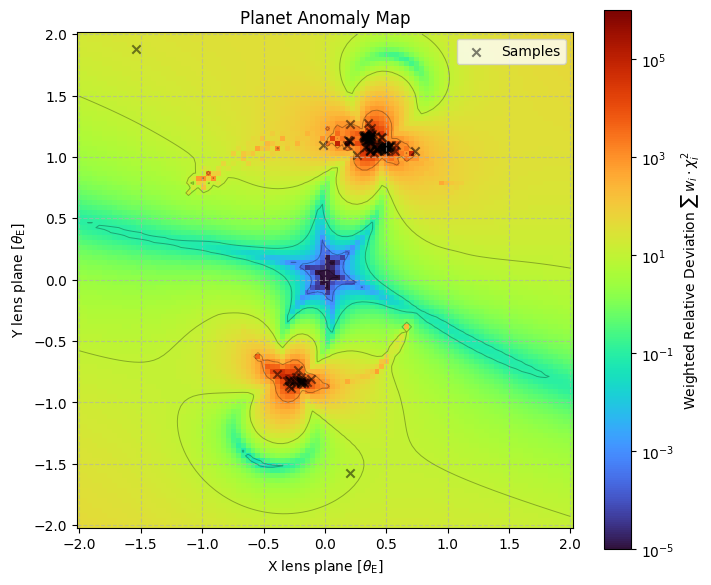

In [9]:
### Use Heatmap as a Distribution for Initial Values
import lintsampler
from scipy.interpolate import RegularGridInterpolator

# choose what to use as a distribution/statistic
anomaly_statistic = planet_anomaly_map / np.sum(planet_anomaly_map)

# create vectorized function with Grid Interpolator
matrix_interp = RegularGridInterpolator((x_range, y_range), anomaly_statistic.T)

# create sampler and sample points
sampler = lintsampler.LintSampler((x_range, y_range), matrix_interp, vectorizedpdf=True)
n_samples = 100
samples = sampler.sample(n_samples)
x_samples = samples[:,0]
y_samples = samples[:,1]

rd.plot_heatmap(X_grid, Y_grid, planet_anomaly_map, 
                norm=colors.LogNorm(1e-5,1e6),
                add_cbar=True, cbar_label='Weighted Relative Deviation $\\sum \\, w_i \\cdot \\chi_i^2$',
                add_contour=True, add_grid=True, add_tE=False,
                add_trajectory=False, t0=t0, u0=u0, te=te, t=reldev_maps['t'],
                show_plot=False)
plt.title('Planet Anomaly Map')
plt.scatter(x_samples, y_samples, c='k', alpha=0.5, marker='x', label='Samples')
plt.legend()
plt.show()


/home/jakob/projects/microlensing/pyLIMA-docs-revisit/my_project/planet_anomaly_map/reldev_grid.py:191: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  contour = plt.pcolormesh(X, Y, Z,


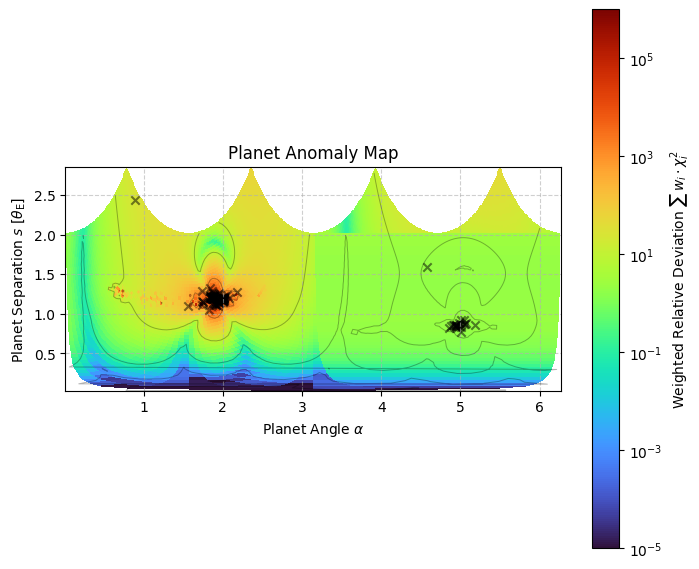

In [10]:
### Convert Init Values from x,y to s,alpha
s_samples = np.hypot(x_samples, y_samples)
alpha_samples = np.arctan2(x_samples, y_samples) + np.pi/2
# wrap alpha around
alpha_samples = np.mod(alpha_samples, 2*np.pi)

# convert the heatmap
s_grid = np.hypot(X_grid, Y_grid)
alpha_grid = np.arctan2(X_grid, Y_grid) + np.pi/2
alpha_grid = np.mod(alpha_grid, 2*np.pi)

# plot
rd.plot_heatmap(alpha_grid, s_grid, planet_anomaly_map, 
                norm=colors.LogNorm(1e-5,1e6),
                add_cbar=True, cbar_label='Weighted Relative Deviation $\\sum \\, w_i \\cdot \\chi_i^2$',
                add_contour=True, add_grid=True, add_tE=False,
                add_trajectory=False, t0=t0, u0=u0, te=te, t=reldev_maps['t'],
                show_plot=False)
plt.title('Planet Anomaly Map')
plt.scatter(alpha_samples, s_samples, c='k', alpha=0.5, marker='x', label='Samples')
plt.xlabel('Planet Angle $\\alpha$')
plt.ylabel('Planet Separation $s$ [$\\theta_{\\rm E}$]')
plt.show()


In [18]:
### Run TRF Fits with these Initial Values

# use pspl params
t0 = pspl_params['t0']
u0 = pspl_params['u0']
te = pspl_params['tE']

# best fit object
best_fit = None

for i, (s, alpha) in enumerate(zip(s_samples, alpha_samples)):
    # create PSBL model
    psbl = PSBL_model.PSBLmodel(my_event)
    
    # create fit, set initial parameters, fit
    fit = TRF_fit.TRFfit(psbl, loss_function='chi2')
    fit.model_parameters_guess = [t0, u0, te, s, 0.001, alpha]
    fit.fit()

    # check chi2
    try:
        if best_fit == None or fit.fit_results[fit.loss_function] < best_fit.fit_results[best_fit.loss_function]:
            best_fit = fit
    except:
        print(f'Fit {i} failed: s={s}, alpha={alpha}\n')


initial_guess  : Initial parameters guess SUCCESS
Using guess:  [2457205.1941240197, 0.31064273065901393, 10.840483880941157, 1.1298910502963389, 0.001, 1.8710704522092896, 9583.458181400982, 12236.545333538295]
Trust Region Reflective fit SUCCESS
best model:
OrderedDict([('t0', np.float64(2457205.2040960155)),
             ('u0', np.float64(0.29218536215852026)),
             ('tE', np.float64(11.277158184464362)),
             ('separation', np.float64(1.0570551701736945)),
             ('mass_ratio', np.float64(0.0009093467877231755)),
             ('alpha', np.float64(1.904934356096982)),
             ('fsource_CTIO_I', np.float64(9304.66471272073)),
             ('ftotal_CTIO_I', np.float64(11924.309132394357)),
             ('chi2', np.float64(363.4462727841809))])
initial_guess  : Initial parameters guess SUCCESS
Using guess:  [2457205.1941240197, 0.31064273065901393, 10.840483880941157, 1.1088323440178143, 0.001, 1.912202868455491, 10128.353778699346, 11912.268963545379]
Trust 

Best fit choosen with a chi^2 of 105.50706657468987 and parameters:
OrderedDict([('t0', np.float64(2457205.2126199882)),
             ('u0', np.float64(0.3058273459039414)),
             ('tE', np.float64(10.865605263367874)),
             ('separation', np.float64(1.2982682406478963)),
             ('mass_ratio', np.float64(0.0009893660955251384)),
             ('alpha', np.float64(1.899687754202809)),
             ('fsource_CTIO_I', np.float64(9874.12652538875)),
             ('ftotal_CTIO_I', np.float64(11986.489749486156)),
             ('chi2', np.float64(105.50706657468987))])


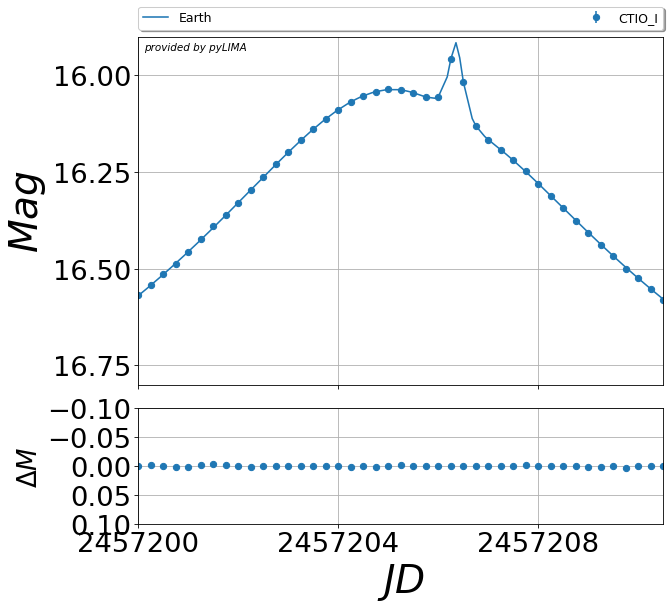

In [19]:
### Give overview over best fit
import pprint

# extract params
best_psbl_params =  OrderedDict(zip(best_fit.priors_parameters.keys(), best_fit.fit_results['best_model']))
best_psbl_params[best_fit.loss_function] = best_fit.fit_results[best_fit.loss_function]

print(f'Best fit choosen with a chi^2 of {best_fit.fit_results['chi2']} and parameters:')
pprint.pprint(best_psbl_params)

# plot
fig, _ = pyLIMA_plots.plot_lightcurves(psbl, best_fit.fit_results['best_model'])
fig.axes[0].set_xlim(*ax_xlim)
fig.axes[0].set_ylim(*ax_ylim)
plt.show()

In [20]:
### Compare best fit params to real values

# compare absolute values
print(f'Comparison of best of parameters:')
print('')
print(f'  simulation       |   best fit')
print(f't0:     {psbl_sim_params[0]} | {best_psbl_params['t0']}')
print(f'u0:     {psbl_sim_params[1]}      | {best_psbl_params['u0']}')
print(f'tE:     {psbl_sim_params[2]}    | {best_psbl_params['tE']}')
print(f's:      {psbl_sim_params[3]}        | {best_psbl_params['separation']}')
print(f'q:      {psbl_sim_params[4]}      | {best_psbl_params['mass_ratio']}')
print(f'alpha:  {psbl_sim_params[5]}        | {best_psbl_params['alpha']}')
print('')
print(f'chi2 of fit: {best_psbl_params['chi2']}')
print('')

# compare the sigma intervals
print('STD-intervals:')
cov = best_fit.fit_results['covariance_matrix']
unc = np.sqrt(np.diag(cov))
a = np.array(psbl_sim_params)
b = np.array(list(best_psbl_params.values())[:-1])
std = np.abs(a - b) / unc
print(f't0:     {std[0]}')
print(f'u0:     {std[1]}')
print(f'tE:     {std[2]}')
print(f's:      {std[3]}')
print(f'q:      {std[4]}')
print(f'alpha:  {std[5]}')

Comparison of best of parameters:

  simulation       |   best fit
t0:     2457205.21 | 2457205.2126199882
u0:     0.309      | 0.3058273459039414
tE:     10.7821    | 10.865605263367874
s:      1.3        | 1.2982682406478963
q:      0.001      | 0.0009893660955251384
alpha:  1.9        | 1.899687754202809

chi2 of fit: 105.50706657468987

STD-intervals:
t0:     2.398637962875055
u0:     1.0813368398572833
tE:     0.9940757492206409
s:      0.7951201795200672
q:      0.8503209694441355
alpha:  0.42197709362198266
